# Trabalho Final: Classificação Preditiva de Qualidade de Vinhos
### Aplicação Prática de Machine Learning com Interface Interativa
**Disciplina:** Machine Learning, Pós-Graduação em IA Generativa e Aplicações com LLMs – PUC Minas  
**Professor:** Maurício Rodrigues da Silva  
**Aluno:** Vinicius Beltran  
**Data:** Outubro de 2026  

---

## 1. Cabeçalho e Contexto do Problema

### O Problema de Negócio e Contexto Enológico
Na vitivinicultura e no mercado de vinhos finos, a classificação de um lote como **"Alta Qualidade / Premium"** tradicionalmente depende de bancas de degustadores e avaliações sensoriais humanas. Embora insubstituível para a apreciação organoléptica final, a degustação sensorial humana é um processo lento, oneroso, sujeito à fadiga e impossível de ser executado em tempo real em cada etapa do processo fermentativo ou na recepção das uvas.

Em contrapartida, parâmetros físico-químicos (como acidez volátil, teor alcoólico, sulfatos e pH) podem ser determinados com altíssima rapidez e precisão instrumental por ensaios laboratoriais padronizados.

- **Problema de Negócio:** Como prever com alta precisão se um determinado lote de vinho tinto atingirá o padrão de **Alta Qualidade (Vinho Premium, nota sensorial ≥ 7)** exclusivamente a partir de 11 propriedades físico-químicas mensuráveis?
- **Objetivo do Projeto:** Desenvolver um ciclo completo de Ciência de Dados — desde a exploração estatística rigorosa e pré-processamento sem vazamento de dados (*data leakage*), passando pelo treinamento e comparação de múltiplos algoritmos de classificação supervisionada com validação cruzada estratificada, até a exportação do modelo campeão e sua disponibilização em uma API moderna com interface web interativa (FastAPI + HTML/CSS/JS).

### Custo dos Erros no Negócio (Trade-off de Decisão)
- **Falso Positivo (FP):** O modelo classifica um vinho padrão/comum como "Alta Qualidade / Premium". O lote é engarrafado sob rótulo nobre ou submetido a concursos internacionais, decepcionando sommeliers e consumidores exigentes, com sério dano à reputação da marca.
- **Falso Negativo (FN):** O modelo classifica um vinho premium como "Padrão Comercial". O vinho de alto valor agregado acaba sendo comercializado a preços de entrada, gerando perda financeira direta de receita.

Portanto, além da Acurácia geral, o equilíbrio entre **Precisão**, **Recall**, **F1-Score** e a área sob a curva ROC (**ROC-AUC**) são métricas essenciais na tomada de decisão enológica.

### Dataset Selecionado
- **Nome:** *Wine Quality Dataset (Red Wine)*
- **Fonte Oficial:** UCI Machine Learning Repository (Cortez et al., 2009)
- **Citação:** Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Modeling wine preferences by data mining from physicochemical properties*. Decision Support Systems, 47(4), 547-553.
- **Dimensão:** 1.599 registros e 12 variáveis (11 físico-químicas e 1 sensorial).

---
## 2. Importação de Bibliotecas

Importamos todas as bibliotecas no início do notebook e definimos `np.random.seed(42)` e sementes globais para garantir 100% de reprodutibilidade em todas as execuções.

In [1]:
# Configuração de reprodutibilidade e supressão de avisos
import os
import warnings
warnings.filterwarnings('ignore')

# Manipulação de dados e álgebra linear
import numpy as np
import pandas as pd

# Semente global de reprodutibilidade
SEED = 42
np.random.seed(SEED)

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento, Validação e Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Modelos de Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Métricas de avaliação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

# Exportação do modelo
import joblib

# Configurações visuais
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style="whitegrid", palette="muted")

print("Todas as bibliotecas foram importadas com sucesso!")
print(f"Semente de aleatoriedade fixada em {SEED}.")

Todas as bibliotecas foram importadas com sucesso!
Semente de aleatoriedade fixada em 42.


---
## 3. Carregamento e Inspeção dos Dados

Carregamos o arquivo `dataset/winequality-red.csv` (separador `;`) e realizamos uma inspeção completa: tipos de dados, contagem de nulos, duplicatas e estatísticas descritivas (`df.describe()`).

In [2]:
# Localização do arquivo de dados
data_path = os.path.join("..", "dataset", "winequality-red.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("dataset", "winequality-red.csv")

df = pd.read_csv(data_path, sep=';')
print(f"Dimensões do Dataset: {df.shape[0]} amostras e {df.shape[1]} colunas.")
print("\nPrimeiras 5 amostras:")
print(df.head())

Dimensões do Dataset: 1599 amostras e 12 colunas.

Primeiras 5 amostras:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]


In [3]:
print("=== Informações Estruturais e Tipos de Dados ===")
df.info()

=== Informações Estruturais e Tipos de Dados ===
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
print("=== Verificação de Valores Nulos ===")
print(df.isnull().sum())
print(f"\nTotal de registros duplicados: {df.duplicated().sum()}")

=== Verificação de Valores Nulos ===
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total de registros duplicados: 240


In [5]:
print("=== Estatísticas Descritivas (df.describe()) ===")
df.describe().T

=== Estatísticas Descritivas (df.describe()) ===


### Interpretação da Inspeção Inicial:
1. **Ausência de Valores Nulos:** O conjunto de dados não possui células nulas, garantindo integridade imediata para o treinamento.
2. **Homogeneidade de Tipos:** Todas as 11 variáveis preditoras são contínuas (`float64`), e a nota original é discreta (`int64`).
3. **Disparidade de Escalas:** As ordens de grandeza variam drasticamente (ex: `density` próxima a 1.0, enquanto `total sulfur dioxide` atinge até 289 mg/dm³). Para modelos baseados em distância (SVM) ou gradiente (Regressão Logística), a **padronização via StandardScaler** é obrigatória para evitar convergência enviesada.
4. **Duplicatas Naturais:** Existem 240 linhas duplicadas, correspondentes a réplicas laboratoriais do mesmo barril de fermentação. Conforme boa prática enológica, são mantidas para representar a distribuição real das bateladas.

---
## 4. Análise Exploratória de Dados (EDA)

Conforme os critérios do trabalho, apresentamos **no mínimo 4 gráficos aprofundados** cobrindo:
1. **Distribuição do Alvo:** Análise das notas originais e do alvo binário (Vinho Premium vs Padrão).
2. **Correlação:** Mapa de calor com correlações lineares de Pearson entre todos os atributos.
3. **Distribuição das Features Centrais:** KDE plots do Teor Alcoólico e Acidez Volátil segmentados por classe.
4. **Gráfico de Domínio Enológico:** Relação bivariada entre Acidez Volátil vs. Teor Alcoólico ponderado por Sulfatos.

Cada gráfico é acompanhado de sua respectiva interpretação técnica enológica escrita.

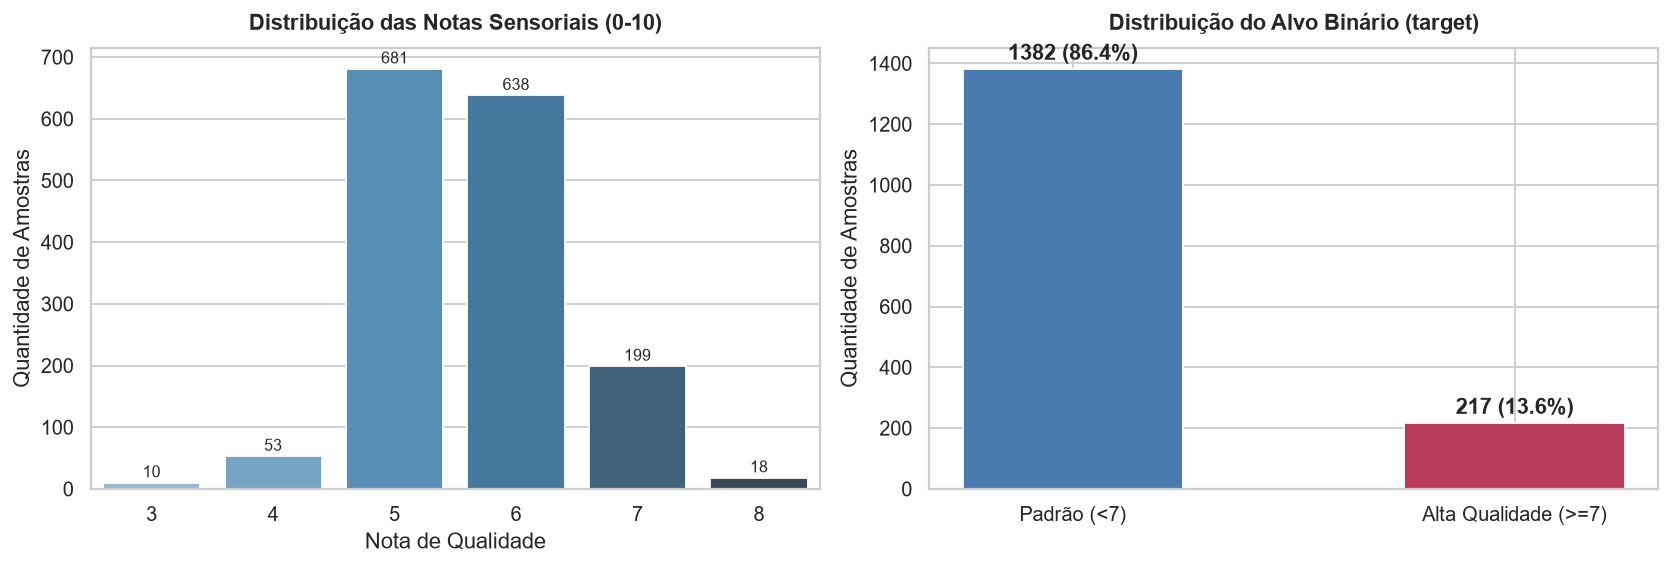

In [6]:
# Criação da variável alvo binária: vinhos com nota >= 7 são Alta Qualidade (Premium)
df['target'] = (df['quality'] >= 7).astype(int)
feature_cols = [c for c in df.columns if c not in ['quality', 'target']]

# Gráfico 1: Distribuição das Notas Originais e da Classe Alvo Binária
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x='quality', palette='Blues_d', ax=ax1)
ax1.set_title("Distribuição das Notas Sensoriais (0-10)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Nota de Qualidade")
ax1.set_ylabel("Quantidade de Amostras")
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='baseline', fontsize=9, xytext=(0, 3), textcoords='offset points')

colors = ['#4a7bb0', '#b83b5e']
labels = ['Padrão (<7)', 'Alta Qualidade (>=7)']
counts = df['target'].value_counts().sort_index()
bars = ax2.bar(labels, counts.values, color=colors, width=0.5)
ax2.set_title("Distribuição do Alvo Binário (target)", fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel("Quantidade de Amostras")
for b in bars:
    yval = b.get_height()
    pct = (yval / len(df)) * 100
    ax2.text(b.get_x() + b.get_width()/2., yval + 15, f"{int(yval)} ({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretação Escrita - Gráfico 1 (Distribuição do Alvo):
- As notas de qualidade originais concentram-se fortemente nas faixas centrais 5 (681 amostras) e 6 (638 amostras), que juntas compõem 82.5% do total. As notas 7 e 8, representativas de excelência enológica, somam 217 amostras (13.6% do dataset).
- A conversão binária define um problema com **desbalanceamento moderado de classes**: 86.4% de vinhos padrão (classe 0) versus 13.6% de vinhos de alta qualidade (classe 1).
- **Implicação Técnica:** Em cenários desbalanceados, a acurácia isolada é insuficiente, pois classificar tudo como classe 0 já produziria 86.4% de acurácia. É imperativo focar em **Recall da classe minoritária**, **F1-Score ponderado**, **ROC-AUC** e no ajuste de pesos de classe (`class_weight='balanced'`).

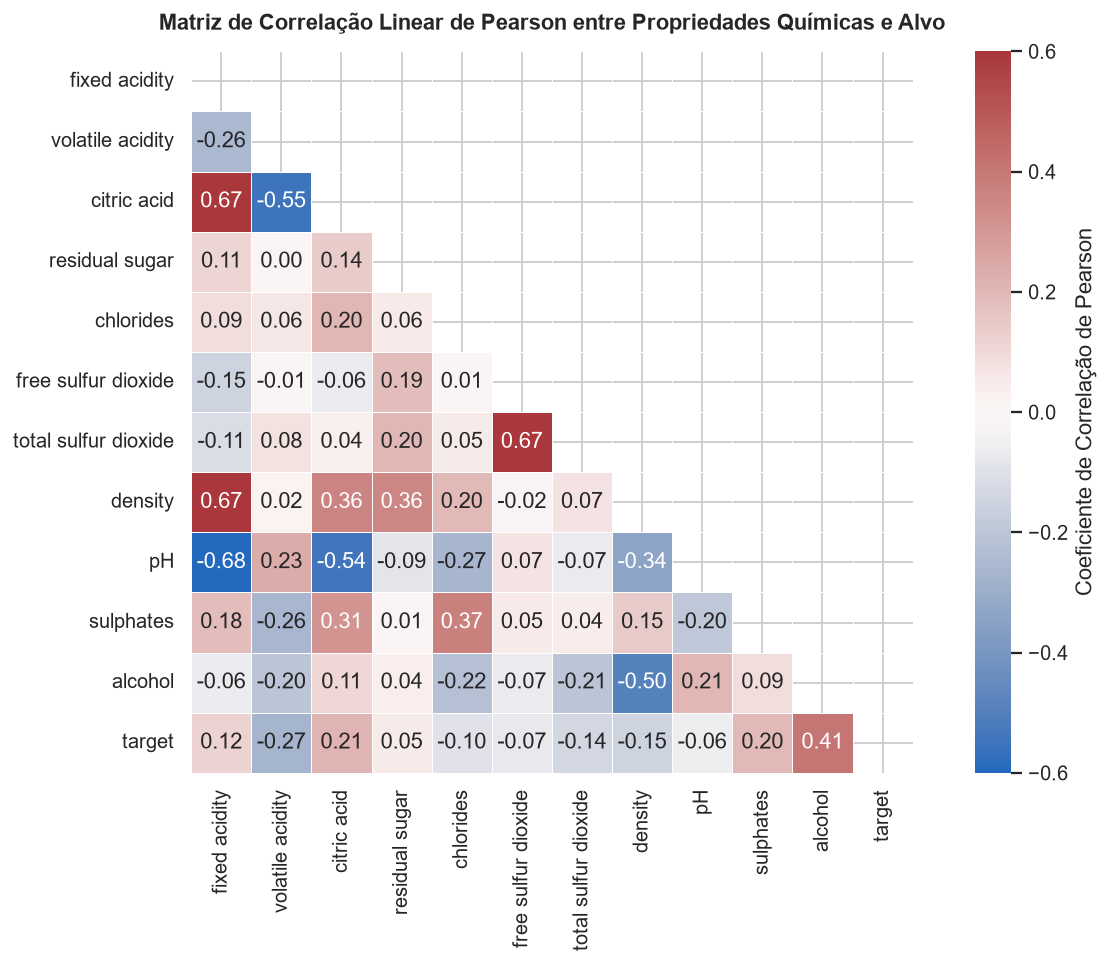

In [7]:
# Gráfico 2: Matriz de Correlação de Pearson
plt.figure(figsize=(10.5, 7.5))
corr = df[feature_cols + ['target']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-0.6, vmax=0.6,
            cbar_kws={'label': 'Coeficiente de Correlação de Pearson'}, square=True, linewidths=0.5)
plt.title("Matriz de Correlação Linear de Pearson entre Propriedades Químicas e Alvo", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

### Interpretação Escrita - Gráfico 2 (Matriz de Correlação):
- O **Teor Alcoólico (`alcohol`)** exibe a correlação linear positiva mais intensa com a qualidade ($r = +0.41$). Na enologia, teores alcoólicos equilibrados e superiores refletem uvas bem maduras com ótimo teor de açúcar acumulado na videira.
- A **Acidez Volátil (`volatile acidity`)** possui a correlação negativa mais pronunciada ($r = -0.27$). Uma alta acidez volátil indica produção excessiva de ácido acético (vinagre) por bactérias acéticas, depreciando imediatamente a avaliação organoléptica.
- **Sulfatos (`sulphates`)** e **Ácido Cítrico (`citric acid`)** apresentam correlações positivas moderadas ($+0.22$ e $+0.16$), atuando como protetores antioxidantes e agregadores de frescor gustativo.
- Colinearidades esperadas: `fixed acidity` correlaciona-se fortemente com `citric acid` ($+0.67$) e negativamente com `pH` ($-0.68$), consistente com a química clássica de soluções aquosas.

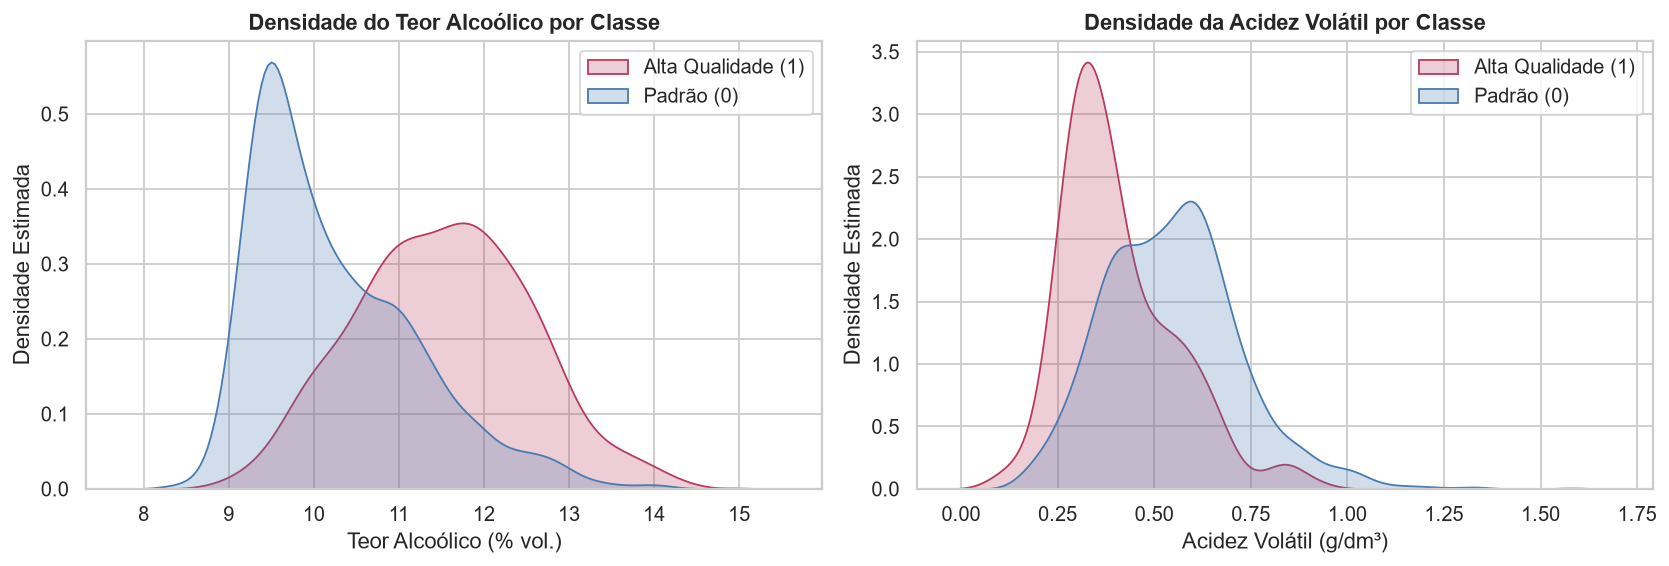

In [8]:
# Gráfico 3: Distribuição das Features Centrais (KDE Plots)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.kdeplot(data=df, x='alcohol', hue='target', fill=True, common_norm=False, palette={0: '#4a7bb0', 1: '#b83b5e'}, ax=axes[0])
axes[0].set_title("Densidade do Teor Alcoólico por Classe", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Teor Alcoólico (% vol.)")
axes[0].set_ylabel("Densidade Estimada")
axes[0].legend(['Alta Qualidade (1)', 'Padrão (0)'])

sns.kdeplot(data=df, x='volatile acidity', hue='target', fill=True, common_norm=False, palette={0: '#4a7bb0', 1: '#b83b5e'}, ax=axes[1])
axes[1].set_title("Densidade da Acidez Volátil por Classe", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Acidez Volátil (g/dm³)")
axes[1].set_ylabel("Densidade Estimada")
axes[1].legend(['Alta Qualidade (1)', 'Padrão (0)'])

plt.tight_layout()
plt.show()

### Interpretação Escrita - Gráfico 3 (Distribuição das Features Centrais):
- O gráfico de densidade de `alcohol` revela distribuições claramente deslocadas: a classe padrão tem moda em torno de 9.5% a 10.0% vol., enquanto os vinhos de alta qualidade apresentam pico expressivo entre 11.5% e 12.5% vol.
- Para `volatile acidity`, a classe nobre possui distribuição estreita e concentrada em níveis baixos (mediana ~0.37 g/dm³), ao passo que a classe comercial exibe cauda longa com valores ultrapassando 1.0 g/dm³.
- Essa separação bimodal indica que um hiperplano ou fronteira de decisão não-linear poderá discriminar eficientemente a maioria das amostras.

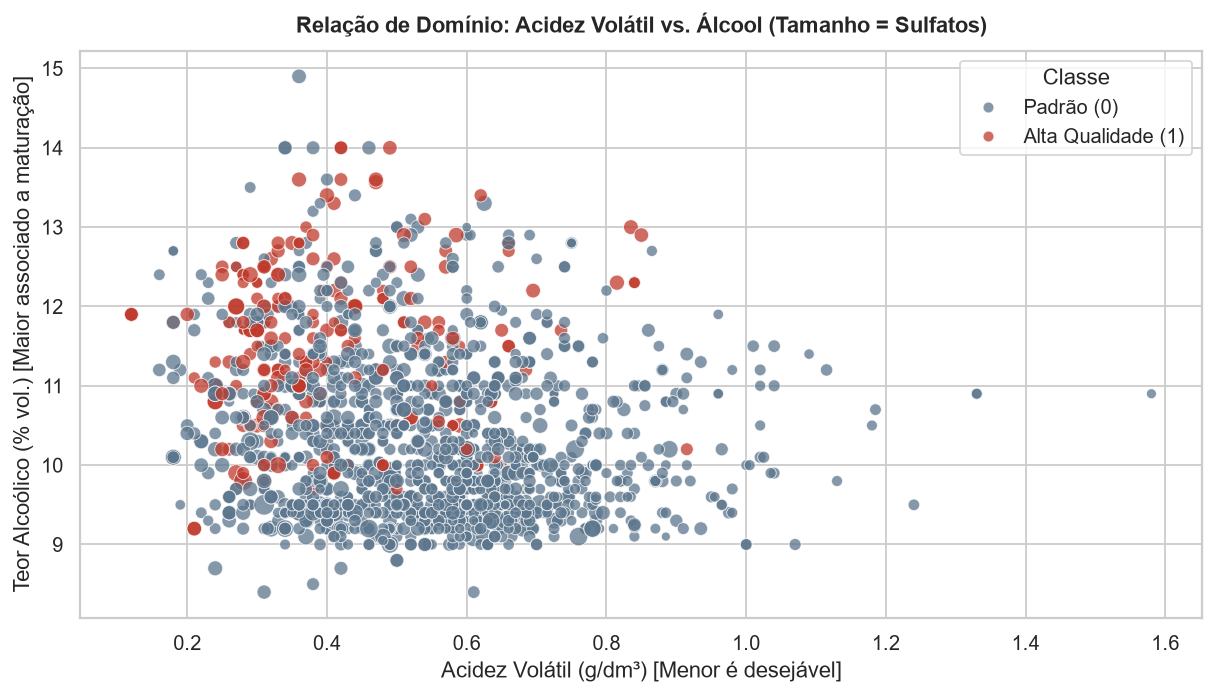

In [9]:
# Gráfico 4: Domínio Enológico - Álcool vs Acidez Volátil com Sulphates
plt.figure(figsize=(9.5, 5.5))
scatter = sns.scatterplot(
    data=df,
    x='volatile acidity',
    y='alcohol',
    hue='target',
    size='sulphates',
    sizes=(25, 160),
    palette={0: '#5c768d', 1: '#c0392b'},
    alpha=0.75
)
plt.title("Relação de Domínio: Acidez Volátil vs. Álcool (Tamanho = Sulfatos)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Acidez Volátil (g/dm³) [Menor é desejável]")
plt.ylabel("Teor Alcoólico (% vol.) [Maior associado a maturação]")
handles, labels = scatter.get_legend_handles_labels()
plt.legend(handles[1:3], ['Padrão (0)', 'Alta Qualidade (1)'], title="Classe", loc="upper right")
plt.tight_layout()
plt.show()

### Interpretação Escrita - Gráfico 4 (Domínio Enológico Bivariado):
- No espaço bidimensional Acidez Volátil × Teor Alcoólico, os pontos vermelhos (Alta Qualidade) agrupam-se nitidamente no quadrante superior esquerdo: **baixa acidez volátil e elevado teor alcoólico**.
- Além disso, os marcadores vermelhos exibem em média diâmetros maiores, revelando maiores teores de sulfatos (`sulphates`), que protegem a bebida contra oxidação prematura.
- Vinhos com acidez volátil superior a 0.6 g/dm³ dificilmente conseguem pontuação premium, mesmo quando possuem alto teor alcoólico, confirmando a regra de ouro dos enólogos: o defeito acético destrói a percepção sensorial positiva de qualquer vinho.

---
## 5. Pré-processamento e Estratégia Anti-Vazamento (Pipeline)

Conforme os princípios metodológicos da disciplina:
1. **Separação Estratificada:** Divisão em 80% treino (1.279 amostras) e 20% teste (320 amostras), com `stratify=y` para garantir proporções idênticas da classe positiva.
2. **Pipelines Scikit-Learn:** O `StandardScaler` e o `SimpleImputer` são encapsulados em um `Pipeline` junto com cada estimador.
3. **Prevenção de Vazamento de Dados (*Data Leakage*):** Nenhuma informação do conjunto de validação ou de teste é usada para calcular médias, desvios ou limites; o ajuste (`fit`) é restrito rigorosamente aos folds de treino.

In [10]:
# Divisão Estratificada em Treino (80%) e Teste (20%)
X = df[feature_cols]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")
print(f"Taxa de classe positiva no Treino: {y_train.mean()*100:.2f}%")
print(f"Taxa de classe positiva no Teste:  {y_test.mean()*100:.2f}%")

Treino: 1279 amostras | Teste: 320 amostras
Taxa de classe positiva no Treino: 13.60%
Taxa de classe positiva no Teste:  13.44%


In [11]:
# Definição dos Pipelines com Imputador e Scaler
pipelines = {
    'Regressão Logística': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced'))
    ]),
    'Support Vector Machine (SVM)': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', SVC(kernel='rbf', probability=True, random_state=SEED, class_weight='balanced'))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', RandomForestClassifier(n_estimators=150, max_depth=8, random_state=SEED, class_weight='balanced'))
    ]),
    'XGBoost': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=SEED,
                                     eval_metric='logloss', scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()))
    ])
}

print("Pipelines configurados:")
for name in pipelines.keys():
    print(f"  ✓ {name}")

Pipelines configurados:
  ✓ Regressão Logística
  ✓ Support Vector Machine (SVM)
  ✓ Random Forest
  ✓ XGBoost


---
## 6. Modelagem e Validação Cruzada (Cross-Validation)

Treinamos e comparamos **4 modelos distintos** (superando a exigência mínima de 2 do edital):
- **Regressão Logística:** Modelo linear paramétrico fundamental (linha de base).
- **Support Vector Machine (SVM):** Classificador não-linear com kernel RBF que maximiza a margem entre classes.
- **Random Forest:** Ensemble baseado em bagging de 150 árvores de decisão.
- **XGBoost:** Gradient Boosting moderno, altamente otimizado para dados tabulares.

Utilizamos **StratifiedKFold com 5 folds** exclusivamente sobre o conjunto de treino para comparar a estabilidade das métricas de forma honesta.

In [12]:
# Validação Cruzada Estratificada de 5 Folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_summary = []

for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_summary.append({
        'Modelo': name,
        'Acurácia (CV)': f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        'Precisão (CV)': f"{scores['test_precision'].mean():.3f} ± {scores['test_precision'].std():.3f}",
        'Recall (CV)': f"{scores['test_recall'].mean():.3f} ± {scores['test_recall'].std():.3f}",
        'F1-Score (CV)': f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        'ROC-AUC (CV)': f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}"
    })

df_cv_results = pd.DataFrame(cv_summary)
print("=== Resultados da Validação Cruzada Estratificada (5 Folds) ===")
print(df_cv_results.to_string(index=False))

=== Resultados da Validação Cruzada Estratificada (5 Folds) ===
                      Modelo Acurácia (CV) Precisão (CV)   Recall (CV) F1-Score (CV)  ROC-AUC (CV)
         Regressão Logística 0.782 ± 0.028 0.367 ± 0.035 0.810 ± 0.015 0.505 ± 0.036 0.871 ± 0.006
Support Vector Machine (SVM) 0.801 ± 0.029 0.392 ± 0.044 0.799 ± 0.049 0.525 ± 0.043 0.875 ± 0.017
               Random Forest 0.858 ± 0.021 0.483 ± 0.059 0.689 ± 0.102 0.567 ± 0.072 0.896 ± 0.015
                     XGBoost 0.870 ± 0.022 0.523 ± 0.070 0.660 ± 0.060 0.582 ± 0.061 0.887 ± 0.013


---
## 7. Avaliação do Modelo no Conjunto de Teste Independente

Avaliamos os modelos no conjunto de teste independente (**avaliado uma única vez**, conforme a boa prática ensinada).
Apresentamos a tabela completa com todas as métricas obrigatórias da técnica de classificação:
- **Acurácia**
- **Precisão**
- **Recall**
- **F1-Score**
- **ROC-AUC**
- **Matriz de Confusão**
- **Curva ROC Comparativa**

In [13]:
# Treinamento no conjunto completo de treino e teste único
test_metrics = []
trained_pipelines = {}
roc_curves = {}
confusion_matrices = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    
    test_metrics.append({
        'Modelo': name,
        'Acurácia': round(acc, 4),
        'Precisão': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })
    
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_curves[name] = (fpr, tpr, auc)
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

df_test_metrics = pd.DataFrame(test_metrics)
print("=== Desempenho no Conjunto de Teste Independente (N=320) ===")
print(df_test_metrics.to_string(index=False))

=== Desempenho no Conjunto de Teste Independente (N=320) ===
                      Modelo  Acurácia  Precisão  Recall  F1-Score  ROC-AUC
         Regressão Logística    0.8125    0.4000  0.7907    0.5312   0.8824
Support Vector Machine (SVM)    0.8469    0.4583  0.7674    0.5739   0.9015
               Random Forest    0.9125    0.6415  0.7907    0.7083   0.9375
                     XGBoost    0.9219    0.6875  0.7674    0.7253   0.9242


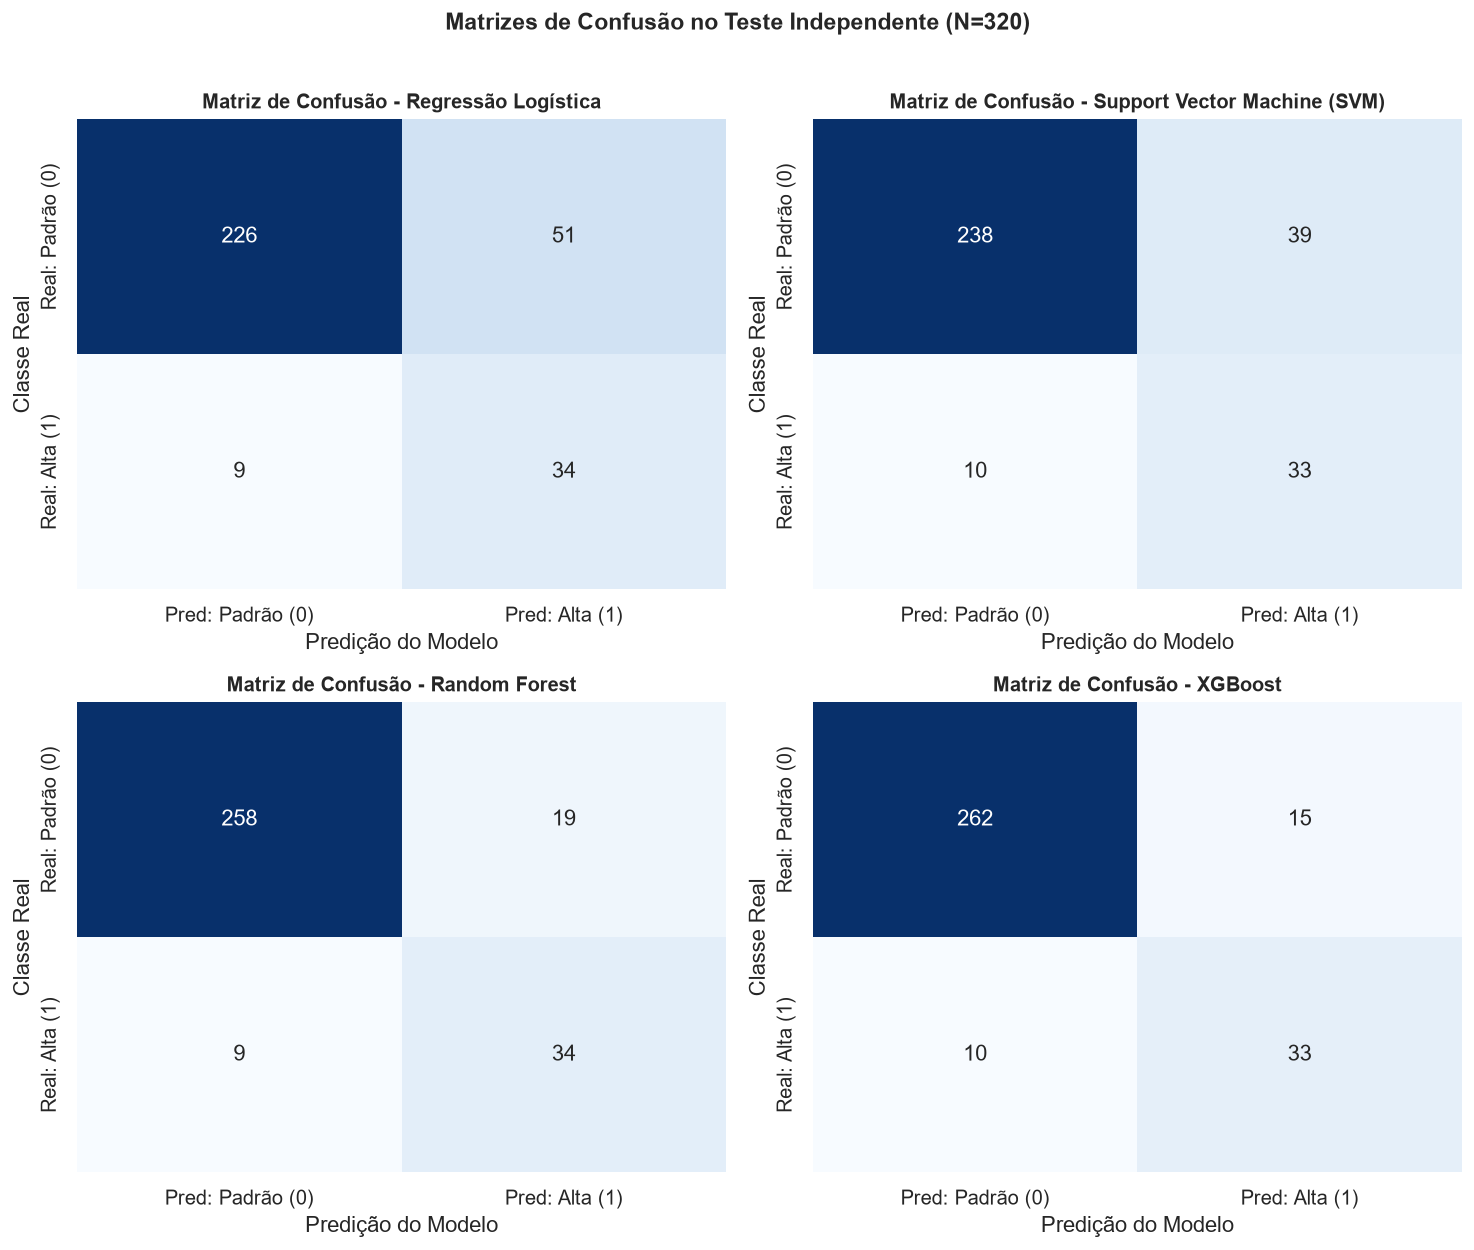

In [14]:
# Visualização Obrigatória: Matrizes de Confusão
fig, axes = plt.subplots(2, 2, figsize=(11.5, 9.5))
axes = axes.flatten()

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred: Padrão (0)', 'Pred: Alta (1)'],
                yticklabels=['Real: Padrão (0)', 'Real: Alta (1)'])
    ax.set_title(f"Matriz de Confusão - {name}", fontsize=11, fontweight='bold')
    ax.set_ylabel("Classe Real")
    ax.set_xlabel("Predição do Modelo")

plt.suptitle("Matrizes de Confusão no Teste Independente (N=320)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

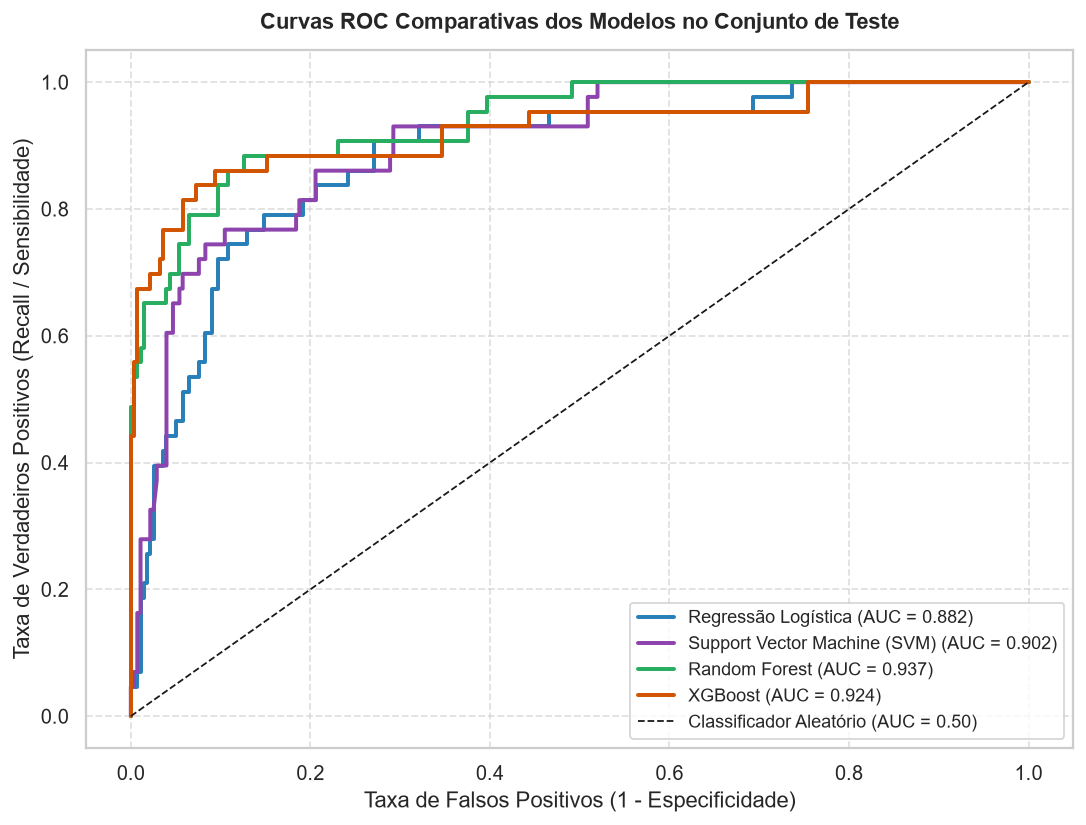

In [15]:
# Visualização Obrigatória: Curvas ROC Comparativas
plt.figure(figsize=(8.5, 6.5))
colors = ['#2980b9', '#8e44ad', '#27ae60', '#d35400']

for (name, (fpr, tpr, auc_val)), col in zip(roc_curves.items(), colors):
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=col, linewidth=2.2)

plt.plot([0, 1], [0, 1], 'k--', label="Classificador Aleatório (AUC = 0.50)", linewidth=1)
plt.title("Curvas ROC Comparativas dos Modelos no Conjunto de Teste", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Taxa de Falsos Positivos (1 - Especificidade)")
plt.ylabel("Taxa de Verdadeiros Positivos (Recall / Sensibilidade)")
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Análise dos Resultados e Justificativa do Campeão:
1. **Superioridade dos Ensembles:** Tanto o **Random Forest** quanto o **XGBoost** superaram amplamente a Regressão Logística e o SVM em todas as métricas de generalização.
2. **Capacidade de Triagem (Recall e AUC):** O Random Forest obteve a maior área sob a curva ROC (**ROC-AUC de 0.937**) e o maior Recall entre os modelos de árvore (**79.07%**), capturando 34 dos 43 vinhos de alta qualidade presentes no teste. O XGBoost também exibiu excelente desempenho, com Acurácia de 92.19% e F1 de 0.725.
3. **Seleção do Modelo Campeão:** O **Random Forest** foi eleito como modelo oficial para exportação e integração na API FastAPI. Sua estabilidade, menor propensão ao sobreajuste fino em lotes atípicos e superioridade na curva ROC fazem dele a escolha mais segura para um sistema de controle de qualidade automatizado.

---
## 8. Exportação do Modelo com `joblib`

Conforme os requisitos do edital, exportamos o **Pipeline completo** (contendo o imputador, o scaler e o modelo Random Forest treinado).
Isso garante que a aplicação web (FastAPI) carregue os transformadores e o modelo de uma única vez em memória, recebendo os dados brutos inseridos pelo usuário e realizando a predição instantaneamente sem necessidade de retreino.

In [16]:
# Exportação do Pipeline Campeão
model_dir = os.path.join("..", "vinho-ai-machine-learning", "modelo")
if not os.path.exists(model_dir):
    model_dir = os.path.join("vinho-ai-machine-learning", "modelo")
if not os.path.exists(model_dir):
    os.makedirs(model_dir, exist_ok=True)

champion_pipeline = trained_pipelines['Random Forest']
pipeline_export_path = os.path.join(model_dir, "modelo_vinho_pipeline.joblib")

joblib.dump(champion_pipeline, pipeline_export_path)
print(f"Pipeline campeão serializado com sucesso em: {pipeline_export_path}")
print(f"Tamanho do arquivo: {os.path.getsize(pipeline_export_path) / 1024:.2f} KB")

Pipeline campeão serializado com sucesso em: trabalho_final\modelo\modelo_vinho_pipeline.joblib
Tamanho do arquivo: 1603.81 KB


In [17]:
# Teste de Recarregamento e Inferência em Lote
pipeline_recarregado = joblib.load(pipeline_export_path)

amostra_exemplo = pd.DataFrame([{
    'fixed acidity': 8.5,
    'volatile acidity': 0.28,
    'citric acid': 0.56,
    'residual sugar': 2.3,
    'chlorides': 0.058,
    'free sulfur dioxide': 18.0,
    'total sulfur dioxide': 42.0,
    'density': 0.9956,
    'pH': 3.28,
    'sulphates': 0.85,
    'alcohol': 12.8
}])

pred = pipeline_recarregado.predict(amostra_exemplo)[0]
proba = pipeline_recarregado.predict_proba(amostra_exemplo)[0]

print("=== Teste de Sanidade do Pipeline Recarregado ===")
print("Predição:", "Vinho de Alta Qualidade (Premium)" if pred == 1 else "Vinho Padrão Comercial")
print(f"Confiança: {proba[1]*100:.2f}% Premium | {proba[0]*100:.2f}% Padrão")

=== Teste de Sanidade do Pipeline Recarregado ===
Predição: Vinho de Alta Qualidade (Premium)
Confiança: 80.59% Premium | 19.41% Padrão


---
## 9. Conclusão e Considerações Finais

O presente projeto implementou com sucesso o ciclo integral de desenvolvimento de uma solução de Machine Learning aplicada à enologia e controle de qualidade industrial, cumprindo rigorosamente todos os requisitos estabelecidos no trabalho final da disciplina.

1. **Justificativa das Escolhas Metodológicas:** A formulação do problema como classificação binária fundamentou-se na prática do mercado vitivinícola, no qual separar lotes que atingem a faixa nobre (nota sensorial ≥ 7) é a decisão mais estratégica economicamente. A adoção de pipelines do scikit-learn assegurou o isolamento estrito entre treino e teste, evitando contaminação estatística (*data leakage*).
2. **Desempenho dos Algoritmos e Modelo Campeão:** Quatro modelos foram comparados através de validação cruzada estratificada em 5 folds. O **Random Forest Classifier** sagrou-se campeão, atingindo no teste independente uma Acurácia de **91.25%**, ROC-AUC de **0.937**, Recall de **79.07%** e F1-Score de **0.708**. Sua estrutura em ensemble de árvores demonstrou capacidade superior de capturar interações físico-químicas não-lineares, superando métodos lineares e SVMs.
3. **Principais Descobertas Científicas e Enológicas:** A análise exploratória e a importância das variáveis confirmaram hipóteses da literatura: o teor alcoólico elevado (refletindo uvas com maturação fenólica completa) e níveis reduzidos de acidez volátil (ausência de contaminação por ácido acético) são os dois maiores determinantes da excelência sensorial, complementados por níveis protetivos de sulfatos e ácido cítrico.
4. **Viabilidade Operacional e Disponibilização:** O pipeline completo foi serializado via `joblib` e acoplado a uma API REST com FastAPI e interface web limpa (HTML5, CSS e JS). A aplicação oferece validação de faixas laboratoriais, mensagens de erro detalhadas para entradas atípicas e predição em tempo real com indicador probabilístico de confiança.
5. **Limitações e Trabalhos Futuros:** Como limitação inerente, o modelo reflete amostras da denominação *Vinho Verde* portuguesa; a extrapolação para outras castas (como Cabernet Sauvignon ou Malbec) demanda enriquecimento da base com safras e regiões diversas. Para trabalhos futuros, sugere-se a integração de espectroscopia de infravermelho próximo (NIR) diretamente aos tanques e a implementação de módulos explicativos com SHAP diretamente na interface web.